# Parte 1: Ingesta Eficiente, DuckDB y EDA Automatizado

In [19]:
# Montar Google Drive
from google.colab import drive
import os
# Montar Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:
# Instalar librerías para leer los archivos .sav (SPSS) y herramientas de EDA (como ydata-profiling o sweetviz)
!pip install -q duckdb pyreadstat ydata-profiling pandas numpy matplotlib seaborn

In [21]:
# Definir rutas
import pandas as pd
import duckdb

# Definir la ruta base del proyecto
BASE_DIR = '/content/drive/MyDrive/Proyecto_EH2025_ML_Caso1'
DATA_DIR = os.path.join(BASE_DIR, 'data')
OUTPUT_DIR = os.path.join(BASE_DIR, 'outputs')

print("Rutas configuradas correctamente:")
print("Data:", DATA_DIR)
print("Outputs:", OUTPUT_DIR)

Rutas configuradas correctamente:
Data: /content/drive/MyDrive/Proyecto_EH2025_ML_Caso1/data
Outputs: /content/drive/MyDrive/Proyecto_EH2025_ML_Caso1/outputs


In [22]:
# 1. Leer los archivos .sav asegurando que las columnas sean compatibles
print("Leyendo archivos de SPSS...")
df_persona = pd.read_spss(os.path.join(DATA_DIR, 'EH2025_Persona.sav'))
df_vivienda = pd.read_spss(os.path.join(DATA_DIR, 'EH2025_Vivienda_1.sav'))

# Limpiar posibles tipos de datos problemáticos (convertir objetos categóricos o arrays a string/numérico si es necesario)
# DuckDB prefiere tipos nativos estándar
for col in df_persona.select_dtypes(include=['category']).columns:
    df_persona[col] = df_persona[col].astype(str)

for col in df_vivienda.select_dtypes(include=['category']).columns:
    df_vivienda[col] = df_vivienda[col].astype(str)

print("¡Archivos leídos con éxito!")
print(f"Persona shape: {df_persona.shape}")
print(f"Vivienda shape: {df_vivienda.shape}")

# 2. Conexión con DuckDB y registro seguro
con = duckdb.connect(database=':memory:')

# Registramos las tablas en DuckDB
con.register('persona', df_persona)
con.register('vivienda', df_vivienda)

print("Tablas registradas en DuckDB correctamente.")

Leyendo archivos de SPSS...
¡Archivos leídos con éxito!
Persona shape: (39485, 276)
Vivienda shape: (12726, 64)
Tablas registradas en DuckDB correctamente.


In [23]:
# Consulta para verificar el cruce entre Vivienda y Persona usando 'folio'
query_check = """
    SELECT
        p.folio,
        p.depto,
        p.area,
        v.depto AS depto_viv
    FROM persona p
    LEFT JOIN vivienda v ON p.folio = v.folio
    LIMIT 5
"""
df_resultado = con.execute(query_check).fetchdf()
display(df_resultado)

,folio,depto,area,depto_viv
0,111-000005-A-0011,Chuquisaca,1.0,Chuquisaca
1,111-000005-A-0011,Chuquisaca,1.0,Chuquisaca
2,111-000005-A-0011,Chuquisaca,1.0,Chuquisaca
3,111-000005-A-0021,Chuquisaca,1.0,Chuquisaca
4,111-000005-A-0021,Chuquisaca,1.0,Chuquisaca


In [25]:
import sweetviz as sv
# 2. Verificar y recargar tablas en DuckDB si no están en memoria
if 'con' not in locals():
    print("Cargando microdatos en memoria...")
    df_persona = pd.read_spss(os.path.join(DATA_DIR, 'EH2025_Persona.sav'))
    df_vivienda = pd.read_spss(os.path.join(DATA_DIR, 'EH2025_Vivienda_1.sav'))

    # Limpiar tipos categóricos para evitar conflictos
    for col in df_persona.select_dtypes(include=['category']).columns:
        df_persona[col] = df_persona[col].astype(str)
    for col in df_vivienda.select_dtypes(include=['category']).columns:
        df_vivienda[col] = df_vivienda[col].astype(str)

    con = duckdb.connect(database=':memory:')
    con.register('persona', df_persona)
    con.register('vivienda', df_vivienda)
    print("Tablas registradas correctamente.")

# 3. Consolidar el dataset analítico con DuckDB
print("Ejecutando consulta SQL para el EDA...")
query_eda = """
    SELECT
        p.folio, p.depto, p.area, p.s01a_02 AS sexo, p.s01a_03 AS edad,
        v.depto AS depto_viv
    FROM persona p
    LEFT JOIN vivienda v ON p.folio = v.folio
"""
df_analisis = con.execute(query_eda).fetchdf()
print(f"Dimensiones del dataset analítico: {df_analisis.shape}")

# 4. Generar el reporte automatizado con Sweetviz
print("Generando el reporte interactivo con Sweetviz (esto puede tomar unos segundos)...")
reporte_sweetviz = sv.analyze(df_analisis)

# 5. Guardar el reporte HTML en la carpeta outputs/
output_html_path = os.path.join(OUTPUT_DIR, 'EDA_Desercion_Escolar.html')
reporte_sweetviz.show_html(output_html_path, open_browser=False)

print(f"¡Reporte EDA generado y guardado exitosamente en:\n{output_html_path}")

Ejecutando consulta SQL para el EDA...
Dimensiones del dataset analítico: (39485, 6)
Generando el reporte interactivo con Sweetviz (esto puede tomar unos segundos)...


                                             |          | [  0%]   00:00 -> (? left)

Report /content/drive/MyDrive/Proyecto_EH2025_ML_Caso1/outputs/EDA_Desercion_Escolar.html was generated.
¡Reporte EDA generado y guardado exitosamente en:
/content/drive/MyDrive/Proyecto_EH2025_ML_Caso1/outputs/EDA_Desercion_Escolar.html


In [26]:
from IPython.display import IFrame
IFrame('/content/drive/MyDrive/Proyecto_EH2025_ML_Caso1/outputs/EDA_Desercion_Escolar.html', width=1000, height=600)

# Parte 2: Análisis Exploratorio y Visualizaciones Interactivas

### Definir la Variable Objetivo de Deserción Escolar en Python

In [27]:
import os
import pandas as pd
import duckdb

# 1. Rutas de trabajo
BASE_DIR = '/content/drive/MyDrive/Proyecto_EH2025_ML_Caso1'
DATA_DIR = os.path.join(BASE_DIR, 'data')
OUTPUT_DIR = os.path.join(BASE_DIR, 'outputs')

# 2. Cargar microdatos (Persona y Vivienda)
print("Cargando microdatos desde la carpeta data...")
df_persona = pd.read_spss(os.path.join(DATA_DIR, 'EH2025_Persona.sav'))
df_vivienda = pd.read_spss(os.path.join(DATA_DIR, 'EH2025_Vivienda_1.sav'))

# Limpiar tipos categóricos
for col in df_persona.select_dtypes(include=['category']).columns:
    df_persona[col] = df_persona[col].astype(str)
for col in df_vivienda.select_dtypes(include=['category']).columns:
    df_vivienda[col] = df_vivienda[col].astype(str)

# 3. Registrar en DuckDB
con = duckdb.connect(database=':memory:')
con.register('persona', df_persona)
con.register('vivienda', df_vivienda)

print("¡Tablas registradas en DuckDB con éxito!")

# 4. Construcción del Dataset Analítico para Deserción Escolar
# Filtramos población en edad escolar (ej. de 4 a 25 años) y extraemos variables clave de educación, demografía y vivienda
query_modelo = """
    SELECT
        p.folio,
        p.depto,
        p.area,
        p.s01a_02 AS sexo,
        CAST(p.s01a_03 AS DOUBLE) AS edad,
        p.s03a_01 AS sabe_leer,
        p.s03a_04 AS matriculado_anio,
        p.s03b_10 AS pasa_clases_actualmente,
        p.cmasi AS condicion_asistencia,
        v.s06a_12 AS uso_electricidad,
        v.s06a_19 AS acceso_internet_viv
    FROM persona p
    LEFT JOIN vivienda v ON p.folio = v.folio
    WHERE CAST(p.s01a_03 AS DOUBLE) BETWEEN 5 AND 20
"""

df_desercion = con.execute(query_modelo).fetchdf()
print(f"Dimensiones del dataset de población en edad escolar (5 a 20 años): {df_desercion.shape}")
display(df_desercion.head())

Cargando microdatos desde la carpeta data...
¡Tablas registradas en DuckDB con éxito!
Dimensiones del dataset de población en edad escolar (5 a 20 años): (11740, 11)


,folio,depto,area,sexo,edad,sabe_leer,matriculado_anio,pasa_clases_actualmente,condicion_asistencia,uso_electricidad,acceso_internet_viv
0,111-000005-A-0021,Chuquisaca,1.0,2. Mujer,20.0,1. Si,1. Si,"1. Sí, presencial",Asiste,1. Si,1. Si
1,111-000005-A-0041,Chuquisaca,1.0,2. Mujer,19.0,1. Si,1. Si,"1. Sí, presencial",Asiste,1. Si,2. No
2,111-000005-A-0041,Chuquisaca,1.0,2. Mujer,15.0,1. Si,1. Si,"1. Sí, presencial",Asiste,1. Si,2. No
3,111-000005-A-0051,Chuquisaca,1.0,2. Mujer,18.0,1. Si,1. Si,4. No,No asiste,1. Si,2. No
4,111-000005-A-0061,Chuquisaca,1.0,2. Mujer,17.0,1. Si,1. Si,"1. Sí, presencial",Asiste,1. Si,2. No


### Variable Objetivo, Visualizaciones Interactivas y Clustering

In [29]:
import plotly.express as px
import plotly.graph_objects as go
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# 1. Ajustar y robustecer la variable objetivo binaria basada en condición de asistencia
print("Valores únicos en condición de asistencia:")
print(df_desercion['condicion_asistencia'].value_counts(dropna=False))

# Marcamos como 1 si el texto indica que no asiste, 0 en caso contrario
df_desercion['desercion'] = df_desercion['condicion_asistencia'].apply(
    lambda x: 1 if ('no asiste' in str(x).lower() or 'no' in str(x).lower()) else 0
)

print(f"\nDistribución ajustada de la variable objetivo (Deserción):")
print(df_desercion['desercion'].value_counts(normalize=True) * 100)

# 2. Visualización Interactiva 1: Tasa de Deserción por Departamento (Gráfico de Barras)
df_depto = df_desercion.groupby('depto')['desercion'].mean().reset_index()
df_depto['tasa_desercion_%'] = df_depto['desercion'] * 100

fig_map = px.bar(
    df_depto,
    x='depto',
    y='tasa_desercion_%',
    title='<b>Tasa de Deserción Escolar por Departamento (Bolivia 2025)</b>',
    text_auto='.2f',
    color='tasa_desercion_%',
    color_continuous_scale='Reds'
)
fig_map.update_layout(xaxis_title='Departamento', yaxis_title='Tasa de Deserción (%)', template='plotly_white')
fig_map.show()

# 3. Visualización Interactiva 2: Sunburst Multivariado corregido (evitando divisiones por cero)
df_multiv = df_desercion.groupby(['depto', 'area', 'sexo']).agg(
    total_estudiantes=('desercion', 'count'),
    total_desercion=('desercion', 'sum')
).reset_index()

df_multiv['tasa_%'] = (df_multiv['total_desercion'] / df_multiv['total_estudiantes']) * 100
df_multiv['tasa_%'] = df_multiv['tasa_%'].fillna(0)

fig_multi = px.sunburst(
    df_multiv,
    path=['depto', 'area', 'sexo'],
    values='total_estudiantes',
    color='tasa_%',
    title='<b>Sunburst Multivariado: Estudiantes y Tasa de Deserción por Departamento, Área y Sexo</b>',
    color_continuous_scale='Viridis'
)
fig_multi.show()

# 4. Segmentación por Clustering (K-Means) para perfiles de riesgo
cluster_data = df_desercion[['edad', 'desercion']].copy()
cluster_data['internet'] = df_desercion['acceso_internet_viv'].apply(lambda x: 1 if '1' in str(x) else 0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(cluster_data)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_desercion['cluster'] = kmeans.fit_predict(X_scaled)

print("\n¡Clustering K-Means aplicado y gráfico Sunburst corregido con éxito!")
print(df_desercion['cluster'].value_counts())

Valores únicos en condición de asistencia:
condicion_asistencia
Asiste            10897
No matriculado      829
No asiste            14
Name: count, dtype: int64

Distribución ajustada de la variable objetivo (Deserción):
desercion
0    92.819421
1     7.180579
Name: proportion, dtype: float64



¡Clustering K-Means aplicado y gráfico Sunburst corregido con éxito!
cluster
1    8398
0    2499
2     843
Name: count, dtype: int64


# Parte 3: Modelo de Machine Learning y Explainability

Dimensiones de X para entrenamiento: (11740, 5)
Distribución de la clase objetivo:
desercion
0    10897
1      843
Name: count, dtype: int64

--- Random Forest (Sin Fuga de Datos) ---
AUC-ROC Promedio (CV 5-folds): 0.8679 (+/- 0.0141)

--- XGBoost (Sin Fuga de Datos) ---
AUC-ROC Promedio (CV 5-folds): 0.8788 (+/- 0.0131)


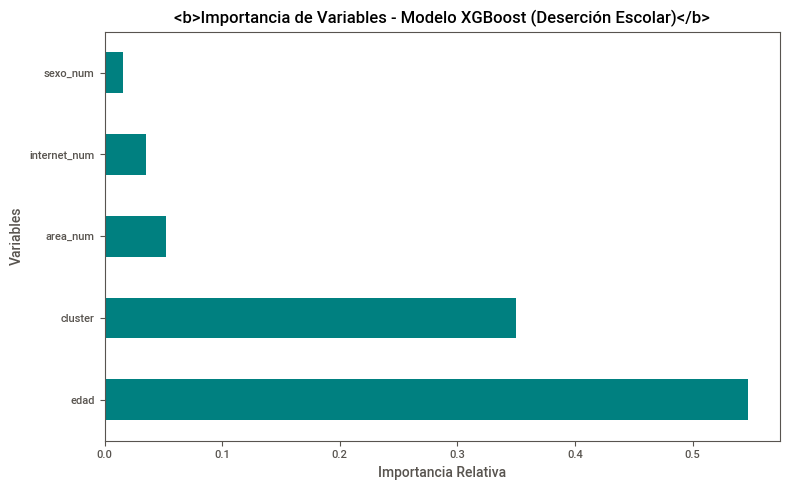

In [31]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
import xgboost as xgb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Preparación limpia de variables (Evitando Data Leakage)
df_ml = df_desercion.copy()

# Codificación de variables categóricas
df_ml['sexo_num'] = df_ml['sexo'].apply(lambda x: 1 if 'Mujer' in str(x) else 0)
df_ml['area_num'] = df_ml['area'].apply(lambda x: 1 if '1' in str(x) else 0) # 1: Urbana, 2: Rural
df_ml['internet_num'] = df_ml['acceso_internet_viv'].apply(lambda x: 1 if '1' in str(x) else 0)

# 2. Re-hacer el Clustering SIN incluir la variable objetivo (deserción)
# Solo usamos edad, área e internet para agrupar perfiles socioeconómicos
cluster_features = df_ml[['edad', 'area_num', 'internet_num']].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(cluster_features)

from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_ml['cluster'] = kmeans.fit_predict(X_scaled)

# 3. Definir Features (X) y Target (y) limpios
features = ['edad', 'sexo_num', 'area_num', 'internet_num', 'cluster']
X = df_ml[features].fillna(0)
y = df_ml['desercion']

print(f"Dimensiones de X para entrenamiento: {X.shape}")
print(f"Distribución de la clase objetivo:\n{y.value_counts()}")

# 4. Configurar Validación Cruzada Estratificada
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 5. Modelo Random Forest con validación rigurosa
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_scores = cross_val_score(rf_model, X, y, cv=cv, scoring='roc_auc')

print(f"\n--- Random Forest (Sin Fuga de Datos) ---")
print(f"AUC-ROC Promedio (CV 5-folds): {rf_scores.mean():.4f} (+/- {rf_scores.std():.4f})")

# 6. Modelo XGBoost con validación rigurosa
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=4,
    random_state=42,
    scale_pos_weight=12
)
xgb_scores = cross_val_score(xgb_model, X, y, cv=cv, scoring='roc_auc')

print(f"\n--- XGBoost (Sin Fuga de Datos) ---")
print(f"AUC-ROC Promedio (CV 5-folds): {xgb_scores.mean():.4f} (+/- {xgb_scores.std():.4f})")

# Entrenar modelo final para la gráfica de importancia real
xgb_model.fit(X, y)

# 7. Gráfico de Importancia de Variables Real
plt.figure(figsize=(8, 5))
feat_importances = pd.Series(xgb_model.feature_importances_, index=features)
feat_importances.nlargest(5).plot(kind='barh', color='teal')
plt.title('<b>Importancia de Variables - Modelo XGBoost (Deserción Escolar)</b>')
plt.xlabel('Importancia Relativa')
plt.ylabel('Variables')
plt.tight_layout()
plt.show()

In [36]:
# Listar librerias utilizadas para generar requirements.txt
import os
import importlib.metadata

# Ruta raíz de tu proyecto en Google Drive
BASE_DIR = '/content/drive/MyDrive/Proyecto_EH2025_ML_Caso1'
req_path = os.path.join(BASE_DIR, 'requirements.txt')

# Lista de librerías utilizadas en las 4 partes del proyecto
librerias = [
    'duckdb',
    'pyreadstat',
    'sweetviz',
    'plotly',
    'scikit-learn',
    'xgboost',
    'pandas',
    'numpy',
    'matplotlib',
    'seaborn'
]

lineas_req = []
for lib in librerias:
    try:
        version = importlib.metadata.version(lib)
        lineas_req.append(f"{lib}=={version}\n")
    except importlib.metadata.PackageNotFoundError:
        lineas_req.append(f"{lib}\n")

# Guardar el archivo requirements.txt en Google Drive
with open(req_path, 'w', encoding='utf-8') as f:
    f.writelines(lineas_req)

print(f"¡Archivo requirements.txt generado con éxito en:\n{req_path}\n")
print("Contenido generado:")
print("".join(lineas_req))

¡Archivo requirements.txt generado con éxito en:
/content/drive/MyDrive/Proyecto_EH2025_ML_Caso1/requirements.txt

Contenido generado:
duckdb==1.3.2
pyreadstat==1.3.7
sweetviz==2.3.3
plotly==5.24.1
scikit-learn==1.6.1
xgboost==3.4.1
pandas==2.2.3
numpy==2.3.5
matplotlib==3.10.0
seaborn==0.13.2



In [37]:
# Crar .gitignore
import os

# Definir la ruta de la carpeta raíz de tu proyecto en Drive
BASE_DIR = '/content/drive/MyDrive/Proyecto_EH2025_ML_Caso1'
gitignore_path = os.path.join(BASE_DIR, '.gitignore')

# Contenido estándar para excluir archivos pesados, carpetas de sistema y entornos
gitignore_content = """# Datos pesados de la encuesta (Evita subir archivos .sav o .csv grandes a GitHub)
data/
*.sav
*.dta
*.csv
*.parquet

# Entornos virtuales y cachés de Python
__pycache__/
*.py[cod]
*$py.class
env/
venv/
.venv/
.ipynb_checkpoints/

# Reportes pesados en HTML generados por Sweetviz
outputs/*.html

# Archivos del sistema operativo
.DS_Store
Thumbs.db
"""

# Escribir el archivo en Drive
with open(gitignore_path, 'w', encoding='utf-8') as f:
    f.write(gitignore_content)

print(f"¡Archivo .gitignore creado con éxito en:\n{gitignore_path}")

¡Archivo .gitignore creado con éxito en:
/content/drive/MyDrive/Proyecto_EH2025_ML_Caso1/.gitignore
